# CHE211F Mini-Design: Raw Water Pumping Station, Devon AB

Calculation appendix for the raw water pipeline from the North Saskatchewan River to the Devon WTP clarifiers.

1. Pipe sizing and head losses for five design velocities (0.5, 1, 2, 3, 5 m/s at 150 L/s)
2. System curves vs. 1, 2 and 3 pumps in parallel, operating points and power
3. Pipe + pump capital cost and 20 years of electricity, and the recommended design
4. Cavitation check (NPSHA vs. NPSHR = 8 m)
5. HGL and EGL for the recommended design at peak flow

All inputs and assumptions are in Section 1.

## 1. Inputs and assumptions

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# Water at 20 C and site data
g = 9.81            # m/s^2
rho = 998.2         # kg/m^3
mu = 1.002e-3       # Pa.s
P_atm = 101.3e3     # Pa (given)
P_v = 2.339e3       # Pa, vapour pressure at 20 C

# Pipe roughness in m. ASSUMPTION: textbook values, the brief does not give them.
eps = {"HDPE": 0.0015e-3, "CS": 0.045e-3}

# Flows
Q_avg = 0.050       # m^3/s
Q_peak = 0.150      # m^3/s
velocities = [0.5, 1.0, 2.0, 3.0, 5.0]   # m/s, candidate design velocities

# Elevations
z_river = 630.0     # m. ASSUMPTION: minimum river level used for every case (worst case)
z_pump = 632.0      # m, pump centreline
z_clarifier = 658.0 # m

# Suction lines (one per pump, HDPE)
L_suction = 5.0     # m
V_suction = 1.5     # m/s at 50 L/s per pump
K_entrance = 0.50
K_suction_fittings = 2*0.39 + 0.10   # 2 elbows + 1 gate valve

# Table 1: location, cumulative horizontal distance x (m), elevation z (m)
loc = [0,   1,   2,   3,   4,   5,   6,   7,   8,   9,   10,  11,  12,  13]
x   = [0,   10,  13,  15,  19,  22,  26,  32,  35,  39,  42,  45,  55,  67]
z   = [632, 637, 638, 639, 640, 641, 642, 643, 644, 645, 646, 650, 651, 658]

# Segment i runs from location i to location i+1 (13 segments).
# ASSUMPTION: materials follow the brief's text (0-1 HDPE, 1-10 CS, 10-13 HDPE).
# Table 1 labels location 1 as CS, which conflicts (memo question 1).
material = ["HDPE"] + ["CS"]*9 + ["HDPE"]*3
# 'main' carries the full flow (0 to 11), 'branch' carries half (11 to 13)
section = ["main"]*11 + ["branch"]*2

# Table 2: fittings at each location -> (total K, which pipe velocity to use)
K_fittings = {
    1:  (0.51 + 0.62,     "main"),     # reducer + expander
    2:  (2*0.39,          "main"),     # 2 elbows
    4:  (2*0.39,          "main"),
    6:  (2*0.39,          "main"),
    10: (2*0.39,          "main"),
    11: (0.51,            "branch"),   # reducer. ASSUMPTION: uses the downstream (branch) velocity
    12: (6*0.39 + 3*0.10, "branch"),   # 6 elbows + 3 gate valves
    13: (6*0.39 + 2*0.10, "branch"),   # 6 elbows + 2 gate valves
}
K_exit = 1.0        # ASSUMPTION: discharge into an open clarifier, velocity head is lost

# Table 3: one pump
pump_Q = np.array([0, 10, 20, 30, 40, 50, 60, 65, 70, 75]) / 1000   # m^3/s
pump_H = np.array([100, 98, 96, 85, 69, 52, 31, 20, 8, 0])           # m
eta = 0.608         # ASSUMPTION: used for both brake and electrical power (no motor efficiency given)
NPSHR = 8.0         # m
NPSH_margin = 1.0   # m. ASSUMPTION: margin wanted above NPSHR
n_installed = 3

# Costs
cost_rate = {"HDPE": 250, "CS": 300}   # $/m = D^2 * rate
elec_price = 0.0288     # $/kWh
annual_volume = 805000  # m^3/yr
years = 20

## 2. Pipe sizing and segment lengths

Continuity: $D = \sqrt{4Q/(\pi V)}$. Main line at 150 L/s, each branch at 75 L/s, each suction line at 50 L/s and 1.5 m/s.
Actual segment length: $L = \sqrt{\Delta x^2 + \Delta z^2}$.

In [2]:
def diameter(Q, V):
    return math.sqrt(4*Q / (math.pi*V))

D_suction = diameter(Q_avg, V_suction)

seg_L = []
for i in range(len(x) - 1):
    dx = x[i+1] - x[i]
    dz = z[i+1] - z[i]
    seg_L.append(math.sqrt(dx**2 + dz**2))

D_main = {}
D_branch = {}
for V in velocities:
    D_main[V] = diameter(Q_peak, V)
    D_branch[V] = diameter(Q_peak/2, V)

segment_table = pd.DataFrame({"from": loc[:-1], "to": loc[1:], "L (m)": seg_L,
                              "material": material, "section": section})
size_table = pd.DataFrame({"V (m/s)": velocities,
                           "D_main (m)": [D_main[V] for V in velocities],
                           "D_branch (m)": [D_branch[V] for V in velocities]})

print(f"Suction line diameter: {D_suction:.3f} m (each of 3 lines)")
display(segment_table)
display(size_table)

Suction line diameter: 0.206 m (each of 3 lines)


,from,to,L (m),material,section
0,0,1,11.180,HDPE,main
1,1,2,3.162,CS,main
2,2,3,2.236,CS,main
3,3,4,4.123,CS,main
4,4,5,3.162,CS,main
5,5,6,4.123,CS,main
6,6,7,6.083,CS,main
7,7,8,3.162,CS,main
8,8,9,4.123,CS,main
9,9,10,3.162,CS,main


,V (m/s),D_main (m),D_branch (m)
0,0.500,0.618,0.437
1,1.000,0.437,0.309
2,2.000,0.309,0.219
3,3.000,0.252,0.178
4,5.000,0.195,0.138


## 3. Head losses and the system curve

- Friction (Darcy–Weisbach): $h_f = f\,\dfrac{L}{D}\,\dfrac{V^2}{2g}$, with $f$ from Colebrook (iterated), or $64/Re$ if laminar.
- Fittings: $h_m = K\,\dfrac{V^2}{2g}$ at the local velocity.
- One flow path is counted: 1 suction line + main line + 1 clarifier branch + exit.

`path_losses()` lists every loss along the path in order. The system curve adds them up, and the HGL/EGL in Section 7
walks through the same list, so the two always agree.

In [3]:
def velocity(Q, D):
    return Q / (math.pi * D**2 / 4)

def vel_head(Q, D):
    return velocity(Q, D)**2 / (2*g)

def friction_factor(Re, e, D):
    if Re < 2300:
        return 64 / Re
    f = 0.02                      # starting guess, then iterate Colebrook
    for i in range(30):
        f = (-2*math.log10(e/(3.7*D) + 2.51/(Re*math.sqrt(f))))**-2
    return f

def friction_loss(Q, D, L, mat):
    Re = rho * velocity(Q, D) * D / mu
    f = friction_factor(Re, eps[mat], D)
    return f * (L/D) * vel_head(Q, D)

def flow_in(sec, Q, Dm, Db):
    # Flow and diameter of the 'main' line or one 'branch'
    if sec == "main":
        return Q, Dm
    return Q/2, Db

def path_losses(Q, Dm, Db, n_pumps):
    # Each step: name, x, z, head loss, and the flow/diameter of the pipe just after it
    qs = Q / n_pumps
    steps = []
    steps.append({"name": "suction entrance", "x": -L_suction, "z": z_river,
                  "loss": K_entrance*vel_head(qs, D_suction), "q": qs, "D": D_suction})
    h = friction_loss(qs, D_suction, L_suction, "HDPE") + K_suction_fittings*vel_head(qs, D_suction)
    steps.append({"name": "suction pipe + fittings", "x": 0, "z": z_pump, "loss": h, "q": qs, "D": D_suction})
    steps.append({"name": "pump", "x": 0, "z": z_pump, "loss": 0.0, "q": Q, "D": Dm})

    for i in range(len(seg_L)):
        q, D = flow_in(section[i], Q, Dm, Db)
        steps.append({"name": f"pipe {i}-{i+1}", "x": x[i+1], "z": z[i+1],
                      "loss": friction_loss(q, D, seg_L[i], material[i]), "q": q, "D": D})
        if i+1 in K_fittings:
            K, sec = K_fittings[i+1]
            qk, Dk = flow_in(sec, Q, Dm, Db)
            next_sec = section[i+1] if i+1 < len(section) else "branch"
            qn, Dn = flow_in(next_sec, Q, Dm, Db)
            steps.append({"name": f"fittings at {i+1}", "x": x[i+1], "z": z[i+1],
                          "loss": K*vel_head(qk, Dk), "q": qn, "D": Dn})

    steps.append({"name": "exit", "x": x[-1], "z": z_clarifier,
                  "loss": K_exit*vel_head(Q/2, Db), "q": 0.0, "D": Db})
    return steps

H_static = z_clarifier - z_river

def system_head(Q, Dm, Db, n_pumps):
    total = H_static
    for s in path_losses(Q, Dm, Db, n_pumps):
        total += s["loss"]
    return total

# Losses at peak flow with 3 pumps
rows = []
for V in velocities:
    steps = path_losses(Q_peak, D_main[V], D_branch[V], 3)
    suction = steps[0]["loss"] + steps[1]["loss"]
    friction = sum(s["loss"] for s in steps if s["name"].startswith("pipe"))
    minor = sum(s["loss"] for s in steps[3:] if not s["name"].startswith("pipe"))
    rows.append({"V (m/s)": V, "suction (m)": suction, "discharge friction (m)": friction,
                 "discharge fittings + exit (m)": minor, "static (m)": H_static,
                 "H_system at 150 L/s (m)": H_static + suction + friction + minor})
loss_table = pd.DataFrame(rows)
display(loss_table)

,V (m/s),suction (m),discharge friction (m),discharge fittings + exit (m),static (m),H_system at 150 L/s (m)
0,0.500,0.199,0.026,0.139,28.000,28.364
1,1.000,0.199,0.140,0.558,28.000,28.896
2,2.000,0.199,0.761,2.230,28.000,31.190
3,3.000,0.199,2.064,5.018,28.000,35.280
4,5.000,0.199,7.303,13.940,28.000,49.441


## 4. Pump curves, system curves and operating points

Pumps in parallel add flow at the same head: $H_n(Q) = H_1(Q/n)$, linearly interpolated from Table 3.
The operating point is where pump head = system head (solved by bisection: halve the flow interval until the two heads match). Power: $P = \rho g Q H / \eta$.

In [4]:
def pump_head(Q, n):
    return np.interp(Q/n, pump_Q, pump_H)

def operating_point(Dm, Db, n):
    def diff(Q):
        return pump_head(Q, n) - system_head(Q, Dm, Db, n)
    if diff(0.001) < 0:                       # system needs more head than the pumps can give
        return float("nan"), float("nan")
    lo, hi = 0.001, n*pump_Q[-1]              # pump head > system head at lo, < at hi
    for i in range(60):
        mid = (lo + hi) / 2
        if diff(mid) > 0:
            lo = mid
        else:
            hi = mid
    Q = (lo + hi) / 2
    return Q, pump_head(Q, n)

op = {}          # op[(V, n)] = results for design V with n pumps running
for V in velocities:
    for n in [1, 2, 3]:
        Q, H = operating_point(D_main[V], D_branch[V], n)
        op[(V, n)] = {"V (m/s)": V, "pumps": n, "Q (L/s)": Q*1000, "H (m)": H,
                      "Q per pump (L/s)": Q*1000/n, "power (kW)": rho*g*Q*H/eta/1000,
                      "meets 50 L/s": Q >= Q_avg, "meets 150 L/s": Q >= Q_peak}
op_table = pd.DataFrame(list(op.values()))
display(op_table)

,V (m/s),pumps,Q (L/s),H (m),Q per pump (L/s),power (kW),meets 50 L/s,meets 150 L/s
0,0.500,1,61.216,28.324,61.216,27.926,True,False
1,0.500,2,122.358,28.406,61.179,55.979,True,False
2,0.500,3,183.354,28.540,61.118,84.281,True,True
3,1.000,1,61.175,28.415,61.175,27.996,True,False
4,1.000,2,122.038,28.758,61.019,56.525,True,False
5,1.000,3,182.298,29.315,60.766,86.070,True,True
6,2.000,1,60.997,28.807,60.997,28.300,True,False
7,2.000,2,120.691,30.240,60.346,58.781,True,False
8,2.000,3,177.913,32.461,59.304,93.015,True,True
9,3.000,1,60.683,29.497,60.683,28.829,True,False


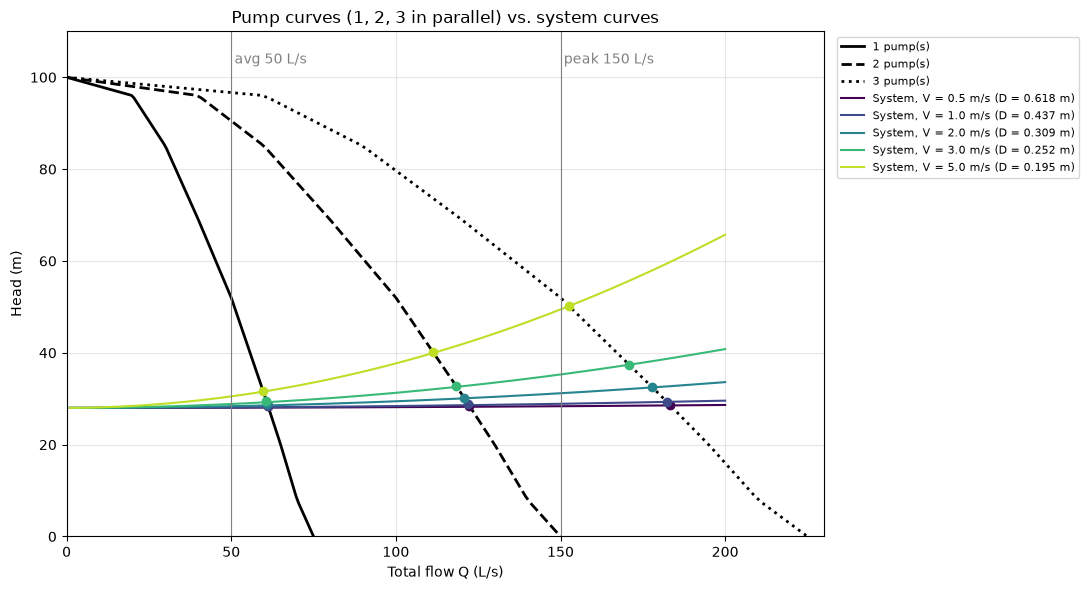

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
for n, style in [(1, "-"), (2, "--"), (3, ":")]:
    Qn = np.linspace(0, n*0.075, 100)
    ax.plot(Qn*1000, pump_head(Qn, n), "k", ls=style, lw=2, label=f"{n} pump(s)")

Qs = np.linspace(0.001, 0.200, 200)
colors = plt.cm.viridis(np.linspace(0, 0.9, len(velocities)))
for c, V in zip(colors, velocities):
    H_sys = [system_head(q, D_main[V], D_branch[V], 3) for q in Qs]
    ax.plot(Qs*1000, H_sys, color=c, label=f"System, V = {V} m/s (D = {D_main[V]:.3f} m)")
    for n in [1, 2, 3]:
        ax.plot(op[(V, n)]["Q (L/s)"], op[(V, n)]["H (m)"], "o", color=c, ms=6)

ax.axvline(50, color="grey", lw=0.8)
ax.axvline(150, color="grey", lw=0.8)
ax.text(51, 103, "avg 50 L/s", color="grey")
ax.text(151, 103, "peak 150 L/s", color="grey")
ax.set_xlabel("Total flow Q (L/s)")
ax.set_ylabel("Head (m)")
ax.set_title("Pump curves (1, 2, 3 in parallel) vs. system curves")
ax.set_xlim(0, 230)
ax.set_ylim(0, 110)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))   # legend outside the plot
plt.tight_layout()
plt.savefig("pump_system_curves.png", dpi=200)
plt.show()

*Note:* system curves are drawn with 3 pumps running. With fewer pumps the suction loss per line is a little higher;
the operating points (dots and table) use the right suction loss for each pump count.

## 5. Cost analysis

- **Pipe capital:** $D^2 \times 250$ (HDPE) or $\times 300$ (CS) \$/m, times length. 3 suction lines, the main line and **both** branches.
- **Pump capital:** $\$1{,}000\sqrt{HP}$ per pump, HP = brake HP per pump at the 3-pump peak operating point.
  All 3 installed pumps are priced. *(ASSUMPTION, memo question 3.)*
- **Electricity:** fewest pumps that give ≥ 50 L/s; hours/yr = 805,000 m³ / Q_op; energy = power × hours.
- **20-year total** = capital + 20 × annual electricity (no inflation or discounting).

In [6]:
def design_costs(V):
    Dm, Db = D_main[V], D_branch[V]

    pipe_cost = n_installed * cost_rate["HDPE"] * D_suction**2 * L_suction
    for i in range(len(seg_L)):
        if section[i] == "main":
            pipe_cost += cost_rate[material[i]] * Dm**2 * seg_L[i]
        else:
            pipe_cost += 2 * cost_rate[material[i]] * Db**2 * seg_L[i]    # two branches

    Q3, H3 = operating_point(Dm, Db, 3)
    feasible = Q3 >= Q_peak                       # False if Q3 is nan
    HP_each = rho*g*(Q3/3)*H3/eta / 745.7
    pump_cost = n_installed * 1000 * math.sqrt(HP_each) if feasible else float("nan")

    n_avg = None
    for n in [1, 2, 3]:
        Qn, Hn = operating_point(Dm, Db, n)
        if Qn >= Q_avg:
            n_avg = n
            break
    if n_avg is None:
        feasible = False
        Qn = Hn = float("nan")

    power = rho*g*Qn*Hn/eta / 1000            # kW
    hours = annual_volume / Qn / 3600
    energy = power * hours                     # kWh/yr
    elec = energy * elec_price                 # $/yr
    total = pipe_cost + pump_cost + years*elec if feasible else float("nan")

    return {"V (m/s)": V, "D_main (m)": Dm, "D_branch (m)": Db, "feasible": feasible,
            "pumps at avg": n_avg, "Q at avg (L/s)": Qn*1000, "hours/yr": hours,
            "energy (kWh/yr)": energy, "pipe capital ($)": pipe_cost, "pump capital ($)": pump_cost,
            "electricity ($/yr)": elec, "20-yr total ($)": total}

costs = pd.DataFrame([design_costs(V) for V in velocities])
display(costs)

best = costs[costs["feasible"]].sort_values("20-yr total ($)").iloc[0]
V_best = best["V (m/s)"]
print(f"Recommended design: V = {V_best} m/s, D_main = {best['D_main (m)']:.3f} m, "
      f"D_branch = {best['D_branch (m)']:.3f} m, 20-yr total = ${best['20-yr total ($)']:,.0f}")
print("Infeasible designs (cannot reach 150 L/s with 3 pumps):", list(costs[~costs["feasible"]]["V (m/s)"]))

,V (m/s),D_main (m),D_branch (m),feasible,pumps at avg,Q at avg (L/s),hours/yr,energy (kWh/yr),pipe capital ($),pump capital ($),electricity ($/yr),20-yr total ($)
0,0.500,0.618,0.437,True,1,61.216,"3,652.793","102,006.305","7,810.755","18,413.836","2,937.782","84,980.223"
1,1.000,0.437,0.309,True,1,61.175,"3,655.267","102,334.676","3,984.955","18,608.244","2,947.239","81,537.972"
2,2.000,0.309,0.219,True,1,60.997,"3,665.946","103,746.561","2,072.055","19,344.369","2,987.901","81,174.443"
3,3.000,0.252,0.178,True,1,60.683,"3,684.884","106,230.351","1,434.422","20,348.175","3,059.434","82,971.278"
4,5.000,0.195,0.138,True,1,59.627,"3,750.171","114,466.314",924.315,"22,274.400","3,296.630","89,131.311"


Recommended design: V = 2.0 m/s, D_main = 0.309 m, D_branch = 0.219 m, 20-yr total = $81,174
Infeasible designs (cannot reach 150 L/s with 3 pumps): []


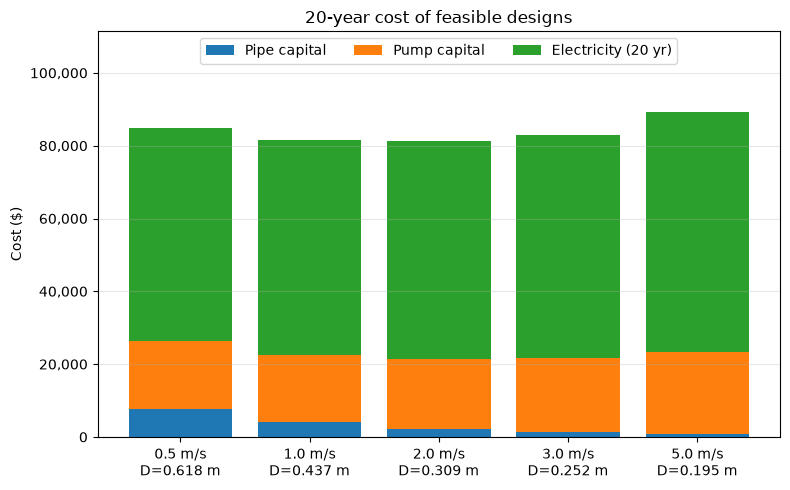

In [7]:
ok = costs[costs["feasible"]]
labels = [f"{V} m/s\nD={D:.3f} m" for V, D in zip(ok["V (m/s)"], ok["D_main (m)"])]
pipe = ok["pipe capital ($)"]
pump = ok["pump capital ($)"]
elec = years * ok["electricity ($/yr)"]

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(labels, pipe, label="Pipe capital")
ax.bar(labels, pump, bottom=pipe, label="Pump capital")
ax.bar(labels, elec, bottom=pipe + pump, label=f"Electricity ({years} yr)")
ax.set_ylabel("Cost ($)")
ax.set_title("20-year cost of feasible designs")
ax.set_ylim(0, 1.25*max(pipe + pump + elec))          # room for the legend above the bars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.legend(loc="upper center", ncol=3)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("cost_comparison.png", dpi=200)
plt.show()

## 6. Cavitation check (NPSHA)

$$NPSHA = \frac{P_{atm} - P_v}{\rho g} - (z_{pump} - z_{river}) - h_{L,suction}$$

at peak flow (3 pumps). If NPSHA < NPSHR + margin, the pump centreline is lowered to
$z_{max} = z_{river} + \frac{P_{atm}-P_v}{\rho g} - h_{L,suction} - (NPSHR + \text{margin})$.
*(ASSUMPTION: lowering the pump only changes NPSHA; the system curve is not recomputed.)*

In [8]:
q_pump = op[(V_best, 3)]["Q per pump (L/s)"] / 1000
steps = path_losses(3*q_pump, D_main[V_best], D_branch[V_best], 3)
h_suction = steps[0]["loss"] + steps[1]["loss"]
h_atm = (P_atm - P_v) / (rho*g)
NPSHA = h_atm - (z_pump - z_river) - h_suction

print(f"Flow per pump at peak:  {q_pump*1000:.1f} L/s")
print(f"(P_atm - P_v)/rho g:    {h_atm:.2f} m")
print(f"Suction lift:           {z_pump - z_river:.2f} m")
print(f"Suction losses:         {h_suction:.3f} m")
print(f"NPSHA:                  {NPSHA:.2f} m  vs  NPSHR = {NPSHR} m")

if NPSHA >= NPSHR + NPSH_margin:
    z_pump_max = z_pump
    print("OK: enough margin, no change needed.")
else:
    z_pump_max = z_river + h_atm - h_suction - (NPSHR + NPSH_margin)
    print(f"Cavitation risk. For a {NPSH_margin} m margin, lower the pump centreline to "
          f"{z_pump_max:.2f} m or below ({z_pump - z_pump_max:.2f} m lower).")

Flow per pump at peak:  59.3 L/s
(P_atm - P_v)/rho g:    10.11 m
Suction lift:           2.00 m
Suction losses:         0.278 m
NPSHA:                  7.83 m  vs  NPSHR = 8.0 m
Cavitation risk. For a 1.0 m margin, lower the pump centreline to 630.83 m or below (1.17 m lower).


## 7. HGL and EGL for the recommended design at peak flow

Start at the river surface (EGL = HGL = 630 m), subtract each loss from `path_losses()` in order and add the pump head
at the pump. $HGL = EGL - V^2/2g$. Fitting losses show as vertical drops. The suction line is at negative distance.

Pump head added: 32.46 m at Q = 177.9 L/s
EGL after the exit loss: 658.000 m (should equal the clarifier level, 658.0 m)


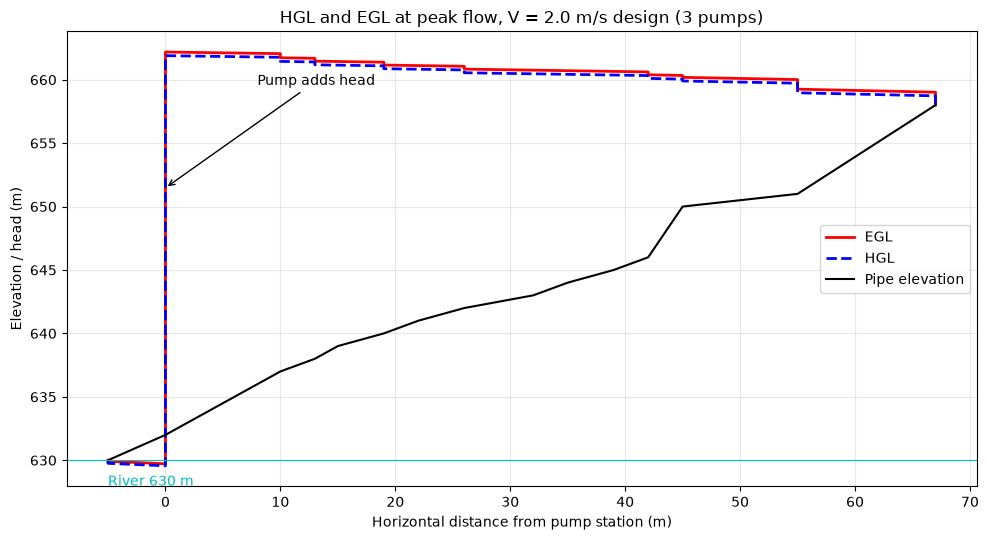

In [9]:
Q_op = op[(V_best, 3)]["Q (L/s)"] / 1000
H_pump = op[(V_best, 3)]["H (m)"]
steps = path_losses(Q_op, D_main[V_best], D_branch[V_best], 3)

xs, egl, hgl, pipe_z = [-L_suction], [z_river], [z_river], [z_river]
E = z_river
for s in steps:
    if s["name"] == "pump":
        E += H_pump
    else:
        E -= s["loss"]
    xs.append(s["x"])
    egl.append(E)
    hgl.append(E - vel_head(s["q"], s["D"]))
    pipe_z.append(s["z"])

print(f"Pump head added: {H_pump:.2f} m at Q = {Q_op*1000:.1f} L/s")
print(f"EGL after the exit loss: {E:.3f} m (should equal the clarifier level, {z_clarifier} m)")

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(xs, egl, "r-", lw=2, label="EGL")
ax.plot(xs, hgl, "b--", lw=2, label="HGL")
ax.plot(xs, pipe_z, "k-", lw=1.5, label="Pipe elevation")
ax.axhline(z_river, color="c", lw=0.8)
ax.text(-L_suction, z_river - 2, "River 630 m", color="c")
ax.annotate("Pump adds head", xy=(0, z_pump + 0.6*H_pump), xytext=(8, z_pump + 0.85*H_pump),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Horizontal distance from pump station (m)")
ax.set_ylabel("Elevation / head (m)")
ax.set_title(f"HGL and EGL at peak flow, V = {V_best} m/s design (3 pumps)")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig("hgl_egl.png", dpi=200)
plt.show()

## 8. Summary

In [10]:
peak = op[(V_best, 3)]
print(f"Recommended design velocity: {V_best} m/s")
print(f"  Main line D:        {best['D_main (m)']:.3f} m")
print(f"  Clarifier branch D: {best['D_branch (m)']:.3f} m")
print(f"  Suction line D:     {D_suction:.3f} m")
print(f"  Average flow:       {int(best['pumps at avg'])} pump, {best['Q at avg (L/s)']:.1f} L/s")
print(f"  Peak flow:          3 pumps, {peak['Q (L/s)']:.1f} L/s at {peak['H (m)']:.1f} m")
print(f"  20-year total:      ${best['20-yr total ($)']:,.0f}")
print(f"  NPSHA at peak:      {NPSHA:.2f} m (NPSHR = {NPSHR} m) -> pump centreline <= {z_pump_max:.2f} m")

Recommended design velocity: 2.0 m/s
  Main line D:        0.309 m
  Clarifier branch D: 0.219 m
  Suction line D:     0.206 m
  Average flow:       1 pump, 61.0 L/s
  Peak flow:          3 pumps, 177.9 L/s at 32.5 m
  20-year total:      $81,174
  NPSHA at peak:      7.83 m (NPSHR = 8.0 m) -> pump centreline <= 630.83 m
